# Physical feedback scenarios already available in Cocoa

Gas cooling and outflows redistribute matter. A two-point correlation measures
pairs of density fluctuations; a three-point correlation also measures how
those fluctuations arrange into triangles. A model can therefore predict the
change in the power spectrum without predicting the change in the bispectrum.

This notebook follows [LSST Y1 EXAMPLE_EVALUATE3](../lsst_y1/EXAMPLE_EVALUATE3.ipynb)
and the [Roman example](../roman_real/EXAMPLE_EVALUATE3.ipynb). It calls the same
**bfmt theory block**, compares all seven of its feedback scenarios, and
propagates their power responses into DES Y3 $\xi_+$ and $\xi_-$. It also calls
**both** installed Burger2025 BACCO emulators to show an independently predicted
power/bispectrum pair. No response in these plots is the artificial teaching
function from [EXAMPLE_JOINT_FEEDBACK](EXAMPLE_JOINT_FEEDBACK.ipynb).

The example points illustrate model choices; they are not feedback fits to DES.
The two-point predictions keep the existing demo's 400 rows, tidal alignment and tidal torquing (TATT) amplitudes,
source reconstruction and recorded negative-source-sample clipping. Their
nonlinear matter baseline changes; quadratic IA loops and covariance do not.
There is no new posterior, Fisher forecast or claim of an exact paper reproduction.

1. Run the existing theory block at the DES cosmology
2. Compare the physical power responses
3. Propagate them into the two-point observables
4. Evaluate the installed paired BACCO models
5. Check extrapolation and save the numerical evidence

The helpers live in [the project wrapper](interface/cosmolike_des_3pcf_feedback_wrappers.py)
and [the theory adapter](python/des3pcf/baryon_scenarios.py). They reuse the
ordinary CosmoLike two-point calculation without modifying its C files.
The new three-point implementation retains its
[Sunao Sugiyama and Rafael Gomes acknowledgements](README.md#acknowledgements).

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import os
from pathlib import Path
import sys
import importlib

for variable in (
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
    "OMP_NUM_THREADS",
):
    os.environ[variable] = "1"
os.environ["OMP_THREAD_LIMIT"] = "4"
# BACCO uses JAX for these small preparation calls; no GPU is requested.
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["TF_NUM_INTRAOP_THREADS"] = "1"
os.environ["TF_NUM_INTEROP_THREADS"] = "1"
os.environ["XLA_FLAGS"] = (
    "--xla_cpu_multi_thread_eigen=false intra_op_parallelism_threads=1"
)
PROJECT = Path.cwd()
if not (PROJECT / "PAPER_TARGETS.md").is_file():
    raise ValueError("Use des_3pcf as this notebook's working directory.")
CORE = PROJECT.parents[1] / "external_modules" / "code" / "cosmolike_core"
sys.path.insert(0, str(PROJECT / "interface"))
sys.path.insert(0, str(CORE))
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
from threadpoolctl import threadpool_info, threadpool_limits
import cosmolike_des_3pcf_feedback_wrappers as feedback

blas_limit = threadpool_limits(limits=1, user_api="blas")
for library in threadpool_info():
    if library["user_api"] == "blas" and library["num_threads"] != 1:
        raise RuntimeError("A loaded BLAS library has more than one worker.")
plots = importlib.import_module(name="cosmolike_notebook_utils.3pcf")

In [2]:
# Figure style of the whole notebook: the shared plotting functions never change
# rcParams, so these lines set every font, tick and grid default.
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams["figure.dpi"] = 90

## 1. Run the existing theory block at the DES cosmology

A Cobaya theory block is a component that computes a requested quantity. Here
CAMB supplies the expansion history and `bfmt` supplies
$R_P(k,z)=P_{\rm feedback}(k,z)/P_{\rm DMO}(k,z)$. The denominator is the model's
gravity-only reference. The adapter requests $k$ in $1/\mathrm{Mpc}$ as bfmt
expects; the saved DES tables use $h/\mathrm{Mpc}$, so the request multiplies
those numbers by $h$. The saved primordial amplitude and neutrino density keep
the background consistent with the saved matter tables.

The [scenario YAML](configs/feedback_scenarios.yaml) copies the LSST/Roman
feedback points: three SP(k) halo-baryon-fraction relations, BCEmu, FLAMINGO,
BACCO and BCemu2025. BACCO is usable at this DES point with $\Omega_b=0.0463$;
the LSST example omitted it because $\Omega_b=0.04$ fell just below its training
box. These models need not produce the same gas distribution or suppression.
They span modeling choices rather than a common parameter prior.

The wrapper computes all two-point rows for each model, restores the original
power arrays, and requires exactly the original prediction. BLAS and OpenMP
use one worker for this example. Installed emulators and the existing prepared
DES tables are required; the notebook does not install packages. Set up missing
models through [Cocoa's documented keys](../../external_modules/code/baryon_suppression/README.md#installation).
The outputs are recalculated on a notebook run, not silently read from a cache.

In [3]:
result = feedback.run_scenarios(
    configuration=PROJECT / "configs/des_y3_joint_feedback_demo.yaml",
    catalog_path=PROJECT / "configs/feedback_scenarios.yaml",
)
print("Exact DMO restoration:", result["record"]["restoration_exact"])
output = PROJECT / "outputs/feedback_scenarios"
output.mkdir(parents=True, exist_ok=True)

[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


SP(k) power law completed; all two-point rows: 400
[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


SP(k) Akino completed; all two-point rows: 400
[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


SP(k) double power law completed; all two-point rows: 400
[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


BCEmu completed; all two-point rows: 400
[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


FLAMINGO completed; all two-point rows: 400
Loading sigma8 emulator...
Sigma8 emulator loaded in memory.
Loading linear emulator...
Linear emulator loaded in memory.
Loading no-wiggles emulator...
No-wiggles emulator loaded in memory.
Loading non-linear emulator...
Nonlinear emulator loaded in memory.
Loading Baryonic Emulator Burger et al. (2025)...
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/baccoemu/bispectrum_baryonic_boost/powerspectra_ratio_bcm_emu_folded.pkl
dict_keys(['n_parameters', 'parameters', 'feature_dimensions', 'scaling_division', 'scaling_subtraction', 'parameter_ranges', 'weights', 'hyper_params', 'param_train_mean', 'param_train_std', 'feature_train_mean', 'feature_train_std'])


... (2 outputs left out)

Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

...BCemu2025 emulator is ready.
[model] *WARNING* Theories {bfmt} do not appear to be actually used for anything


BCemu2025 completed; all two-point rows: 400


Exact DMO restoration: True


## 2. Compare the physical power responses

The vertical axis shows $100(R_P-1)$: a value of $-10$ means ten percent less
power than the gravity-only reference. Two redshifts show how the same model
changes as structures evolve. SP(k)'s three curves differ in the relation
between halo mass and retained baryon fraction; the second figure compares
four emulator families at their stated example points. An emulator is an
interpolator trained on simulations, with a finite parameter and scale range.

The figures show $0.05\lesssim k\lesssim8\,h/\mathrm{Mpc}$, but this is not a
shared calibration interval for every curve. SP(k) uses its low-redshift
clamp below $z=0.125$; each model's Fourier boundaries and interpolation are
those in bfmt. Above each model's maximum redshift the chosen policy returns
unity. The full projection table extends to $1000\,h/\mathrm{Mpc}$, where
several curves are extrapolations. Section 5 tests one consequence of that
extension rather than treating it as calibrated gas physics.

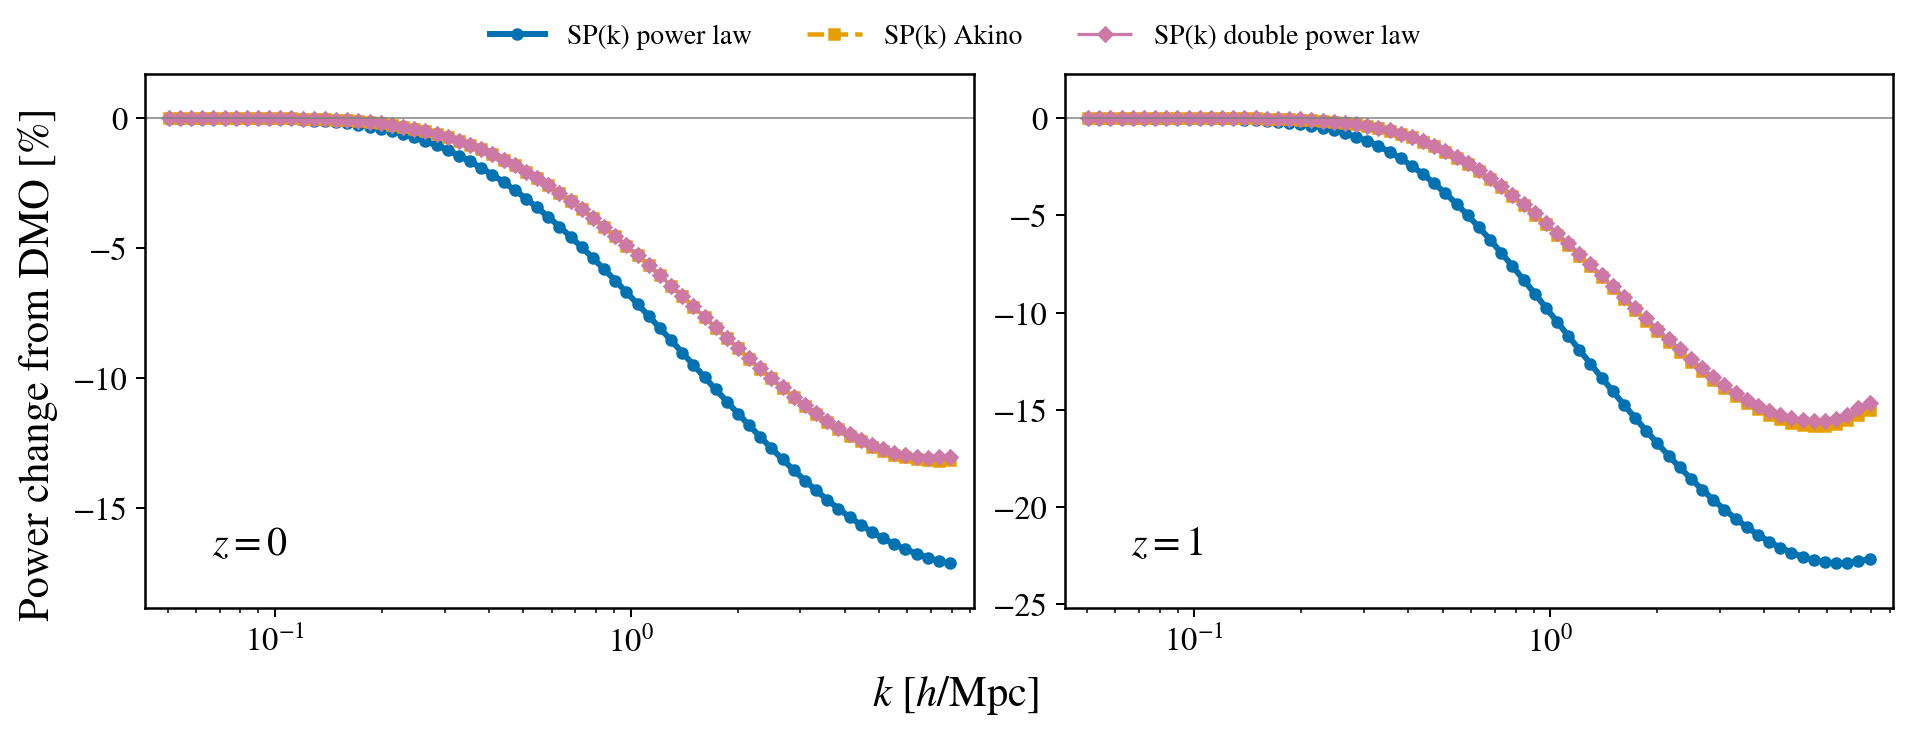

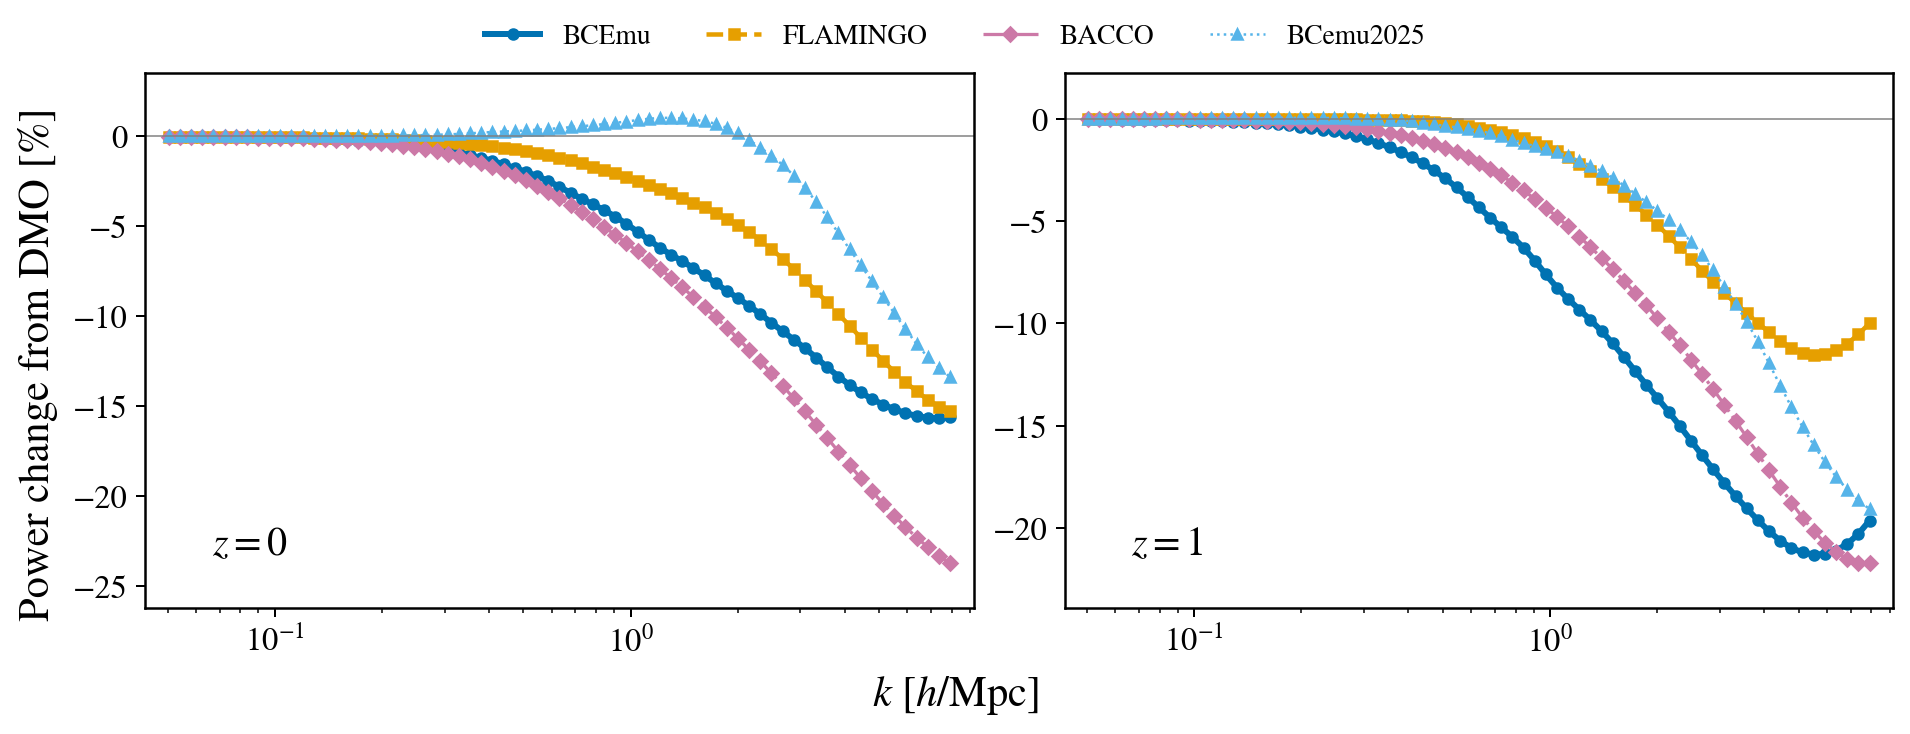

In [4]:
selected_k = (result["k"] >= 0.05) & (result["k"] <= 8.0)
redshift_indices = [int(np.argmin(np.abs(result["z"] - value))) for value in (0., 1.)]
np.testing.assert_allclose(result["z"][redshift_indices], [0., 1.], atol=1.e-12)
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = result["responses"][index, redshift_indices][:, selected_k]
        curves.append((result["k"][selected_k], 100. * (values - 1.)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$z=0$", r"$z=1$"],
        coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
        quantity_label="Power change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"power_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"power_{group}.pdf", pad_inches=0.2)
    plt.show()


## 3. Propagate them into the two-point observables

The nonlinear matter table is multiplied by $R_P(k,z)$ before the ordinary
CosmoLike TATT projection. The figures select source-bin pair (1,1); all 400
rows were calculated. Different responses in $\xi_+$ and $\xi_-$ arise because
they weight the angular power differently. In the small-angle limit,
$\xi_+(\theta)=\int d\ell\,\ell(C_E+C_B)J_0(\ell\theta)/(2\pi)$ and
$\xi_-(\theta)=\int d\ell\,\ell(C_E-C_B)J_4(\ell\theta)/(2\pi)$.
Here $C_E,C_B$ are the two shear-parity power spectra, and $J_0,J_4$ are
Bessel functions with different oscillatory weights. The same small-scale
power change can therefore produce different angular responses. The fixed-cosmology change is not
a parameter constraint: a fit must also vary cosmology and nuisance parameters,
apply the intended cuts, and use their covariance.

For BACCO, $R_P$ describes **cold matter**, meaning cold dark matter (CDM) plus baryons. The existing
Cocoa two-point prescription applies this ratio to total nonlinear power,
which also contains massive neutrinos. We retain that prescription here and
state it as an approximation. Its validity is not established by displaying
these curves. Our DES point has $\sum m_\nu=0.06\,\mathrm{eV}$.
No Map3 curve is manufactured for the six power-only models.

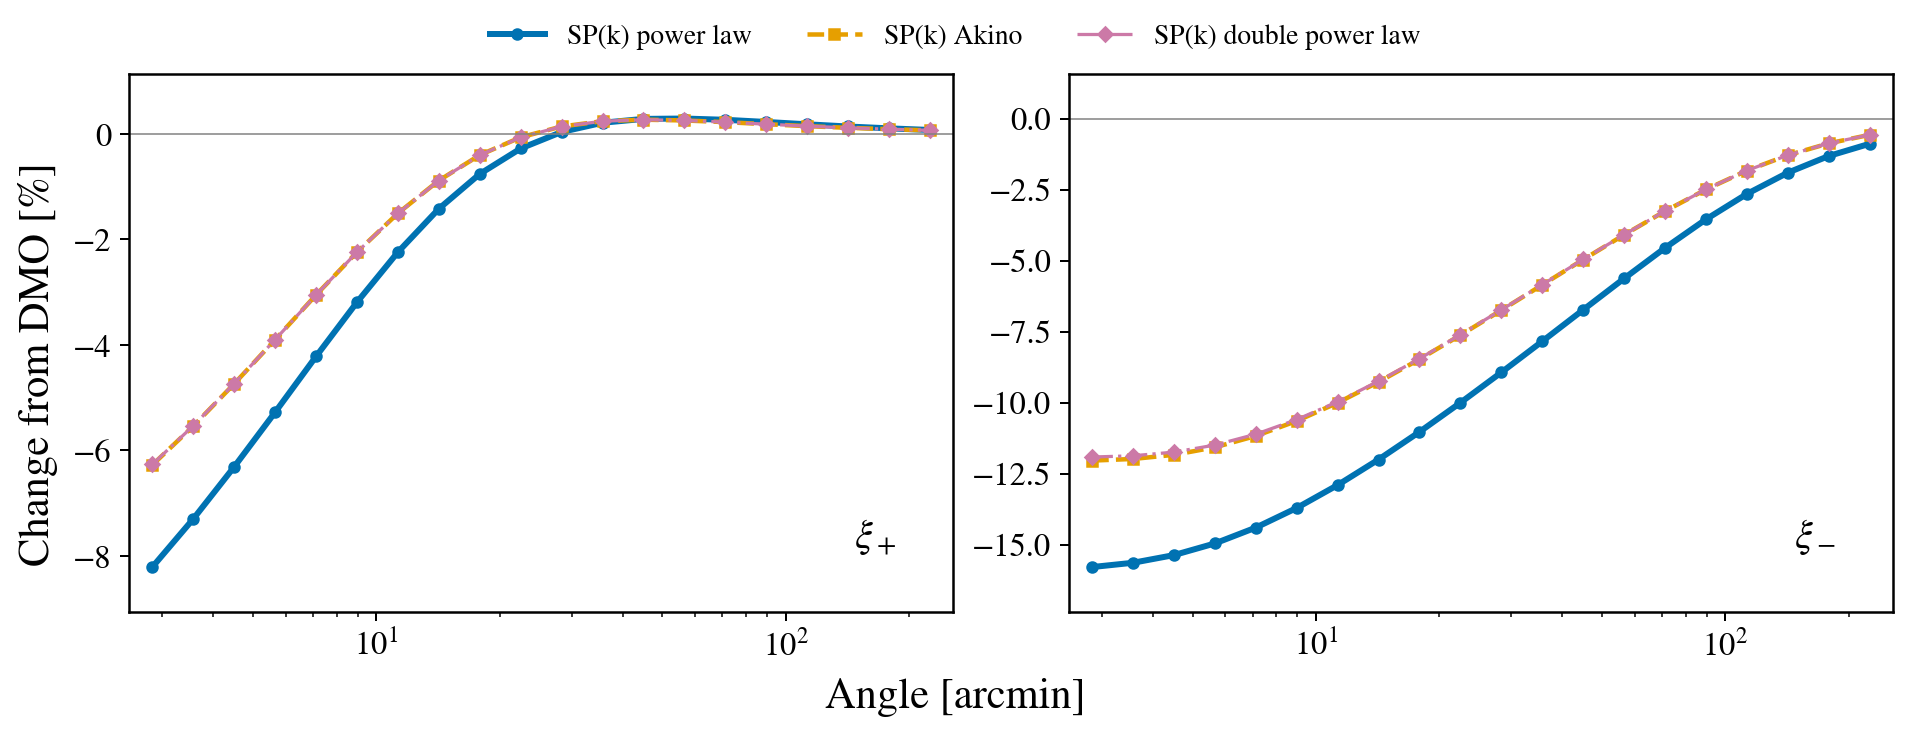

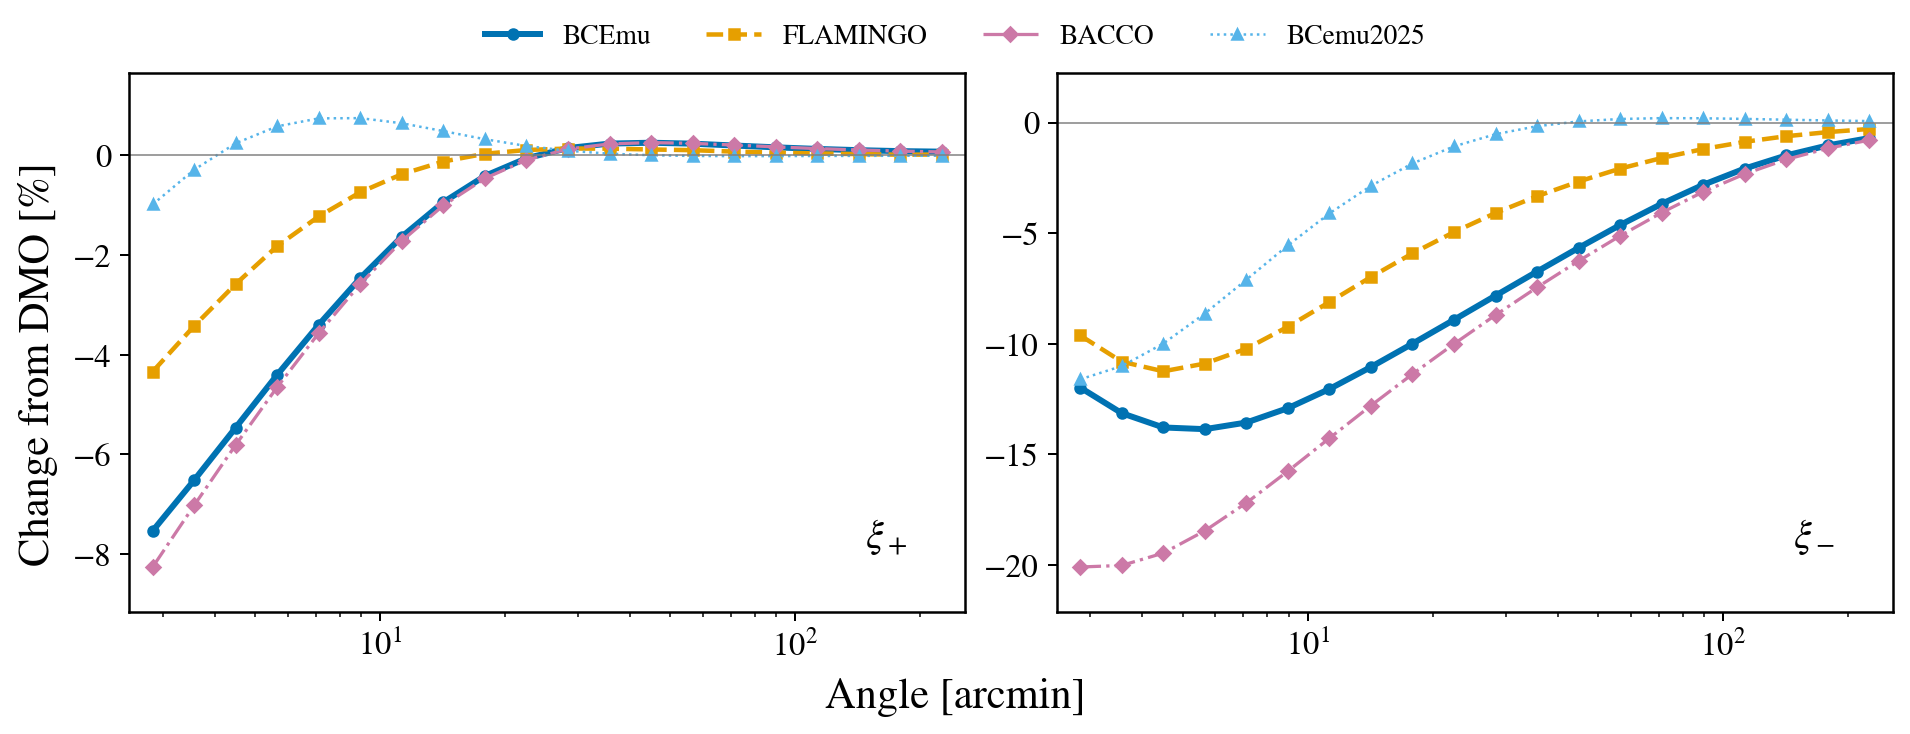

In [5]:
rows = result["rows"]
selected_rows = []
for kind in ("xip", "xim"):
    selected_rows.append(np.flatnonzero(
        (rows.kind == kind) & (rows.bins[:, 0] == 0) & (rows.bins[:, 1] == 0)
    ))
angles = rows.angles[selected_rows[0], 2] * 180. * 60. / np.pi
for group, indices in (("spk", [0, 1, 2]), ("emulators", [3, 4, 5, 6])):
    curves = []
    for index in indices:
        values = []
        for chosen in selected_rows:
            values.append(100. * (
                result["means"][index, chosen] / result["reference"][chosen] - 1.
            ))
        curves.append((angles, np.asarray(values)))
    figure, axes = plots.plot_ia_components(
        components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
        coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
        legend=[result["names"][index] for index in indices],
        marker=["o", "s", "D", "^"], linewidth=[2.4, 1.8, 1.3, 1.0],
        linestyle=["-", "--", "-.", ":"], ncols=2,
        figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
    )
    plots.check_figure_labels(figure=figure)
    figure.savefig(output / f"xi_{group}.png", dpi=150, pad_inches=0.2)
    figure.savefig(output / f"xi_{group}.pdf", pad_inches=0.2)
    plt.show()


## 4. Evaluate the installed paired BACCO models

Burger et al. supply a power response and a separately trained bispectrum
response from the same baryonic correction model. The latter is already in
our installed BACCO package, although bfmt currently exposes only power.
The next cell uses identical cold-matter cosmology and five feedback parameters
for both. It obtains $\sigma_{8,cb}$ from the same BACCO amplitude conversion
used by bfmt, rather than substituting our total-matter $\sigma_8$.

The baryonic correction model (BCM) moves matter around halos using five
shared parameters. All API inputs below are base-ten logarithms, even when a
symbol denotes a scale or slope rather than a mass:

| API coordinate | Physical role |
|---|---|
| `M_c` | Halo mass scale governing gas retention |
| `beta` | Mass dependence of the retained gas fraction |
| `eta` | Extent of ejected gas |
| `M1_z0_cen` | Mass scale in the central-galaxy stellar-mass relation |
| `theta_inn` | Inner gas-profile scale |

For example, `eta=-0.3` means an ejection coordinate of $10^{-0.3}$;
it is not negative gas mass. The YAML lists the actual parameter numbers.

The triangles are equilateral $(k,k,k)$ and scalene $(0.6k,k,1.2k)$. Every side
stays within the installed side bounds; highly squeezed and degenerate
triangles are deliberately absent. The adapter refuses out-of-range inputs,
checks the returned triangle order and counts, and records the weight-file
hashes. This prevents an upstream float32 conversion or row removal from
silently changing which triangles the curves represent. Staying inside side
bounds alone is not an accuracy certificate for every triangle shape.

$R_B$ cannot in general be inferred from $R_P$. The independently predicted
curves below demonstrate the available input; they do not impose
$R_B=R_P^2$ or any other power law. Both responses describe CDM+baryons, not
the full matter field when neutrinos are massive. A calibrated joint-lensing
forecast still needs the matter conversion or a declared approximation, a
tested continuation outside the training domain, and response regeneration
when cosmology/feedback parameters change. None of these requires downloading
the large covariance simulation suite.

Sources: [Burger et al.](https://arxiv.org/abs/2506.18974),
[BACCO documentation](https://baccoemu.readthedocs.io/en/latest/).

Shared cold-matter coordinates: {'omega_cold': 0.28777721867714046, 'omega_baryon': 0.0463, 'sigma8_cold': 0.7898226976394653, 'M_c': 14.0, 'eta': -0.3, 'beta': -0.22, 'M1_z0_cen': 10.5, 'theta_inn': -0.86}


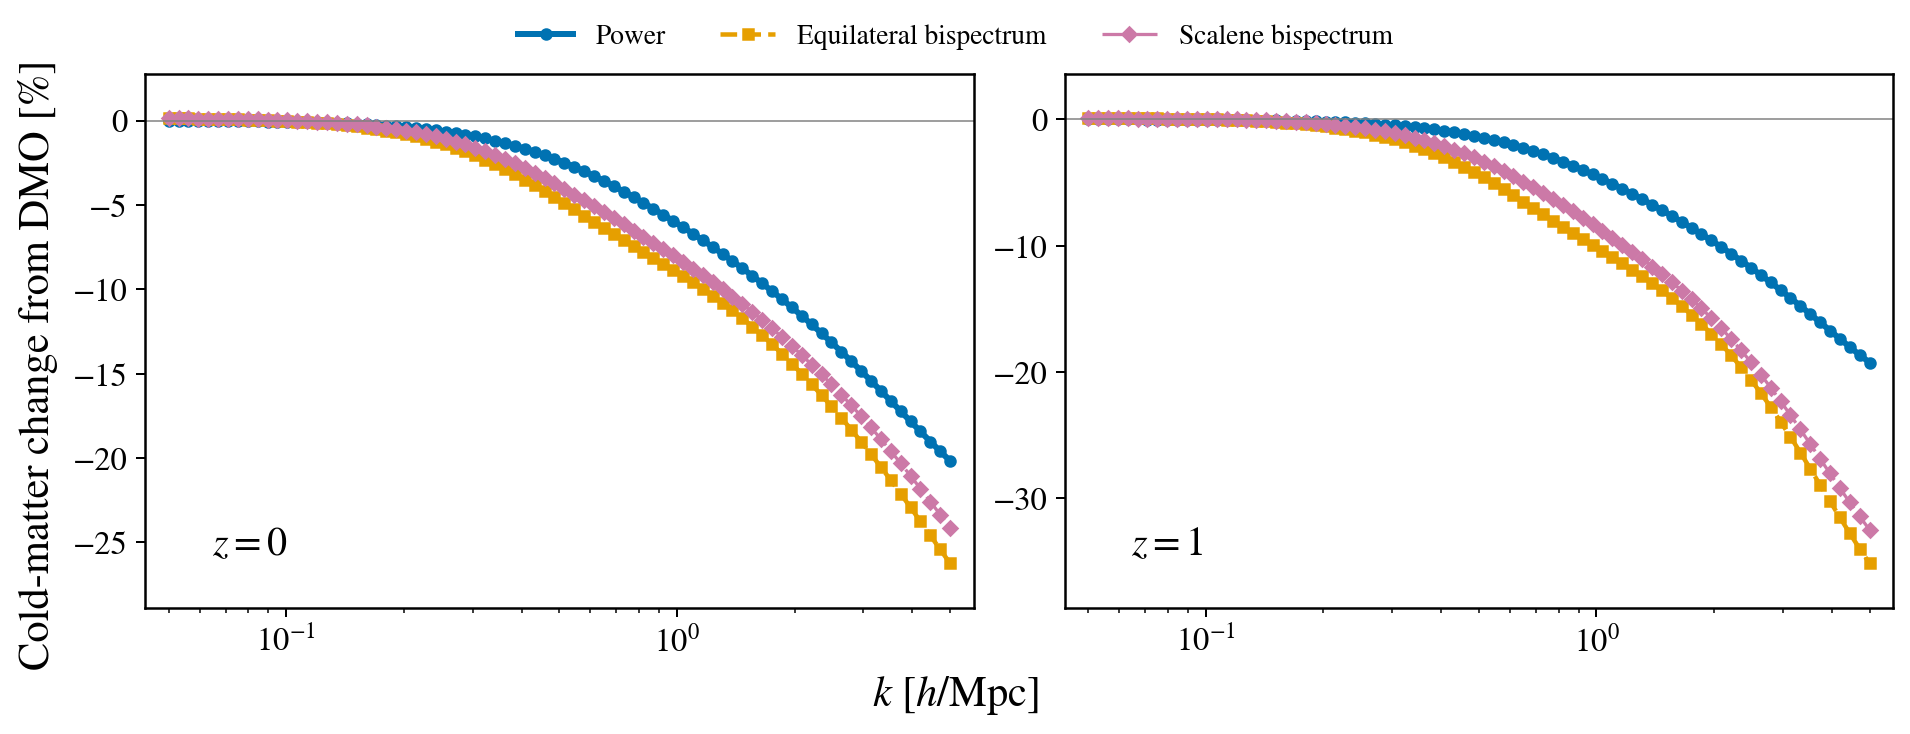

In [6]:
paired = feedback.bacco_diagnostic(records=result["records"])
print("Shared cold-matter coordinates:", paired["record"]["coordinates"])
curves = [(paired["k"], 100. * (paired["power"] - 1.))]
for shape in range(2):
    curves.append((paired["k"], 100. * (paired["bispectrum"][:, shape] - 1.)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$z=0$", r"$z=1$"],
    coordinate_label=r"$k$ [$h/\mathrm{Mpc}$]",
    quantity_label="Cold-matter change from DMO [%]",
    legend=["Power", "Equilateral bispectrum", "Scalene bispectrum"],
    marker=["o", "s", "D"], linewidth=[2.4, 1.8, 1.3],
    linestyle=["-", "--", "-."], ncols=2, figsize=(10.5, 4.0),
    legendfontsize=11, bintextpos=(0.08, 0.10), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "bacco_paired.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "bacco_paired.pdf", pad_inches=0.2)
plt.show()


## 5. Check extrapolation and save the numerical evidence

The original bfmt output is retained at every requested wavenumber. For one
diagnostic only, we replace FLAMINGO's continuation above $10\,h/\mathrm{Mpc}$
by its value at that pivot and recalculate the two-point vector. The figure
compares those two choices. A difference identifies sensitivity to assumed
small-scale power; agreement would not prove every other modeling choice safe.
Holding a boundary constant is also an assumption, not a calibrated extension.

The NPZ records all 400 rows, all seven response tables, the paired BACCO
curves, model points, theory/weight hashes and exact DMO restoration. Its
local numerical checks are not a survey-accuracy certification. The earlier
artificial-pair notebook remains useful for checking the generic native
interface; this notebook supplies the physical-model examples it lacked.

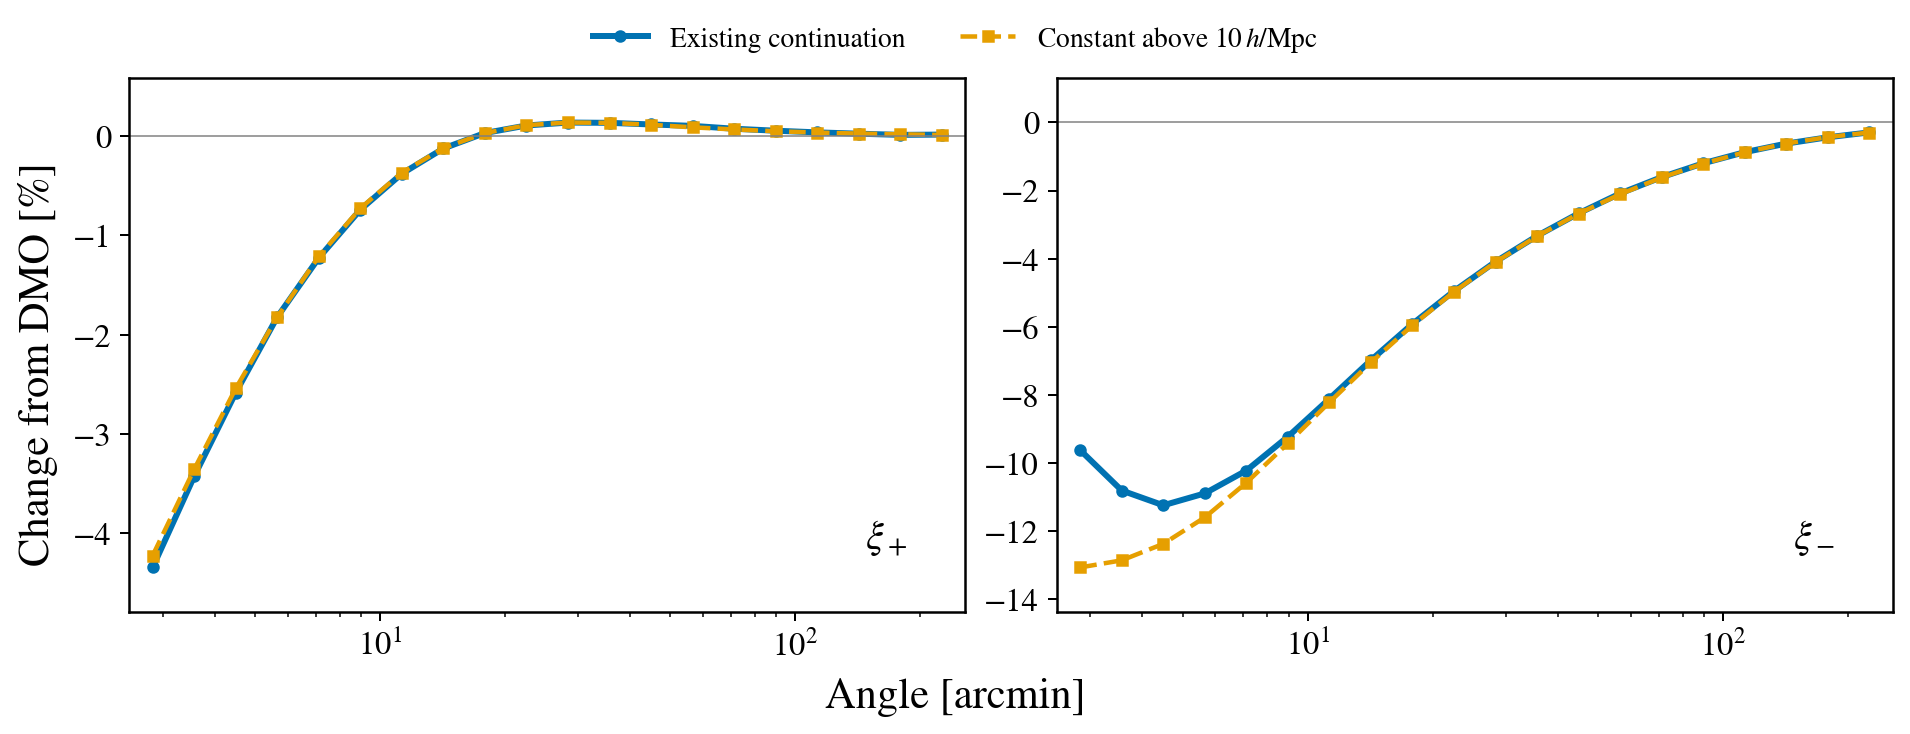

/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_3pcf/runs/feedback_scenarios.npz


In [7]:
curves = []
flamingo = result["names"].index("FLAMINGO")
for mean in (result["means"][flamingo], result["tail_test"]):
    values = []
    for chosen in selected_rows:
        values.append(100. * (mean[chosen] / result["reference"][chosen] - 1.))
    curves.append((angles, np.asarray(values)))
figure, axes = plots.plot_ia_components(
    components=curves, component_labels=[r"$\xi_+$", r"$\xi_-$"],
    coordinate_label="Angle [arcmin]", quantity_label="Change from DMO [%]",
    legend=["Existing continuation", r"Constant above $10\,h/\mathrm{Mpc}$"],
    marker=["o", "s"], linewidth=[2.4, 1.8], linestyle=["-", "--"],
    ncols=2, figsize=(10.5, 4.0), legendfontsize=11, bintextpos=(0.88, 0.12), show=None,
)
plots.check_figure_labels(figure=figure)
figure.savefig(output / "flamingo_tail.png", dpi=150, pad_inches=0.2)
figure.savefig(output / "flamingo_tail.pdf", pad_inches=0.2)
plt.show()
print(feedback.save_scenarios(
    result=result, paired=paired, destination=PROJECT / "runs/feedback_scenarios.npz",
))
